In [1]:
# Data manipulation

import pandas as pd
import numpy as np

In [2]:
# Data visualisation

import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Dataset acquisition

from ucimlrepo import fetch_ucirepo

In [4]:
# Fetch the Default of Credit Card Clients dataset from UCI

credit_data = fetch_ucirepo(id=350)

In [5]:
# Extract independent variables (customer credit information)
X = credit_data.data.features

# Extract dependent variable (next month's default status)
y = credit_data.data.targets

In [7]:
# Combine independent variables and target into a single DataFrame

df = pd.concat([X, y], axis=1)

In [8]:
# Display the number of rows and columns in the dataset

df.shape

(30000, 24)

In [9]:
# Display the first five rows of the dataset

df.head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [10]:
# Display column names, data types and non-null counts

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   X1      30000 non-null  int64
 1   X2      30000 non-null  int64
 2   X3      30000 non-null  int64
 3   X4      30000 non-null  int64
 4   X5      30000 non-null  int64
 5   X6      30000 non-null  int64
 6   X7      30000 non-null  int64
 7   X8      30000 non-null  int64
 8   X9      30000 non-null  int64
 9   X10     30000 non-null  int64
 10  X11     30000 non-null  int64
 11  X12     30000 non-null  int64
 12  X13     30000 non-null  int64
 13  X14     30000 non-null  int64
 14  X15     30000 non-null  int64
 15  X16     30000 non-null  int64
 16  X17     30000 non-null  int64
 17  X18     30000 non-null  int64
 18  X19     30000 non-null  int64
 19  X20     30000 non-null  int64
 20  X21     30000 non-null  int64
 21  X22     30000 non-null  int64
 22  X23     30000 non-null  int64
 23  Y       300

In [11]:
# Generate descriptive statistics for all numerical columns

df.describe().T

,count,mean,std,min,25%,50%,75%,max
X1,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
X2,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
X3,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
X4,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
X5,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
X6,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
X7,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
X8,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
X9,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
X10,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


In [12]:
# Count missing values in each column

df.isnull().sum().sort_values(ascending=False)

X1     0
X2     0
X23    0
X22    0
X21    0
X20    0
X19    0
X18    0
X17    0
X16    0
X15    0
X14    0
X13    0
X12    0
X11    0
X10    0
X9     0
X8     0
X7     0
X6     0
X5     0
X4     0
X3     0
Y      0
dtype: int64

In [13]:
# Display the number of customers in each target class

df['Y'].value_counts()

Y
0    23364
1     6636
Name: count, dtype: int64

In [14]:
# Calculate the percentage distribution of each target class

df['Y'].value_counts(normalize=True) * 100

Y
0    77.88
1    22.12
Name: proportion, dtype: float64

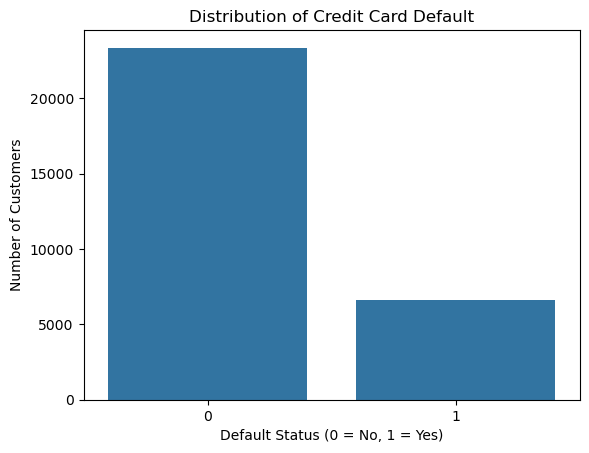

In [15]:
# Visualise the distribution of customers across the two target classes
sns.countplot(data=df, x='Y')

# Add chart labels and title
plt.title('Distribution of Credit Card Default')
plt.xlabel('Default Status (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')

# Display the chart
plt.show()

In [17]:
# Display all column names in the dataset

print(df.columns.tolist())

['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'Y']


In [18]:
# Calculate the default rate for each recent repayment status category
default_by_payment = df.groupby('X6')['Y'].mean() * 100

# Display default rates in ascending order of repayment status
default_by_payment.sort_index()

X6
-2    13.229431
-1    16.778051
 0    12.811291
 1    33.947939
 2    69.141357
 3    75.776398
 4    68.421053
 5    50.000000
 6    54.545455
 7    77.777778
 8    57.894737
Name: Y, dtype: float64

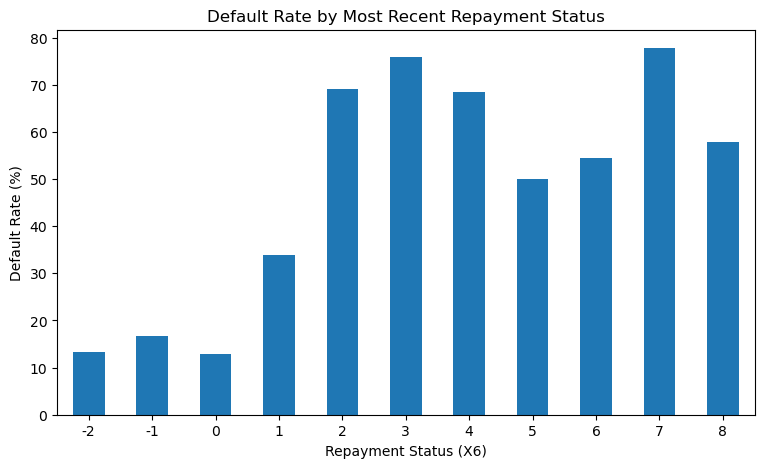

In [19]:
# Calculate default rate for each repayment status category
default_by_payment = df.groupby('X6')['Y'].mean() * 100

# Create a bar chart
default_by_payment.sort_index().plot(kind='bar', figsize=(9, 5))

# Add chart labels and title
plt.title('Default Rate by Most Recent Repayment Status')
plt.xlabel('Repayment Status (X6)')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)

# Display the chart
plt.show()

In [20]:
# Create age groups from the customer's age
df['AGE_GROUP'] = pd.cut(
    df['X5'],
    bins=[20, 30, 40, 50, 60, 80],
    labels=['21-30', '31-40', '41-50', '51-60', '61-79']
)

# Calculate the default rate for each age group
default_by_age = df.groupby('AGE_GROUP', observed=False)['Y'].mean() * 100

# Display the results
default_by_age

AGE_GROUP
21-30    22.437120
31-40    20.433119
41-50    23.297252
51-60    25.237857
61-79    26.838235
Name: Y, dtype: float64

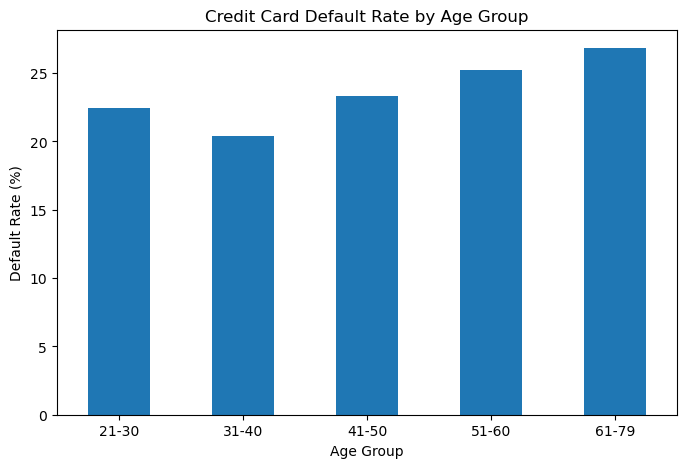

In [21]:
# Create a bar chart showing default rates across age groups
default_by_age.plot(kind='bar', figsize=(8, 5))

# Add chart labels and title
plt.title('Credit Card Default Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)

# Display the chart
plt.show()

In [22]:
# Select the independent variables (X1 to X23)
X = df.drop(columns=['Y', 'AGE_GROUP'])

# Select the dependent variable (Y)
y = df['Y']

# Display the dimensions of features and target
print("Features:", X.shape)
print("Target:", y.shape)

Features: (30000, 23)
Target: (30000,)


In [23]:
# Import the train-test splitting function
from sklearn.model_selection import train_test_split

# Split the data while preserving the target class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the dimensions of each split
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (24000, 23)
Testing features: (6000, 23)
Training target: (24000,)
Testing target: (6000,)


In [24]:
# Import required machine learning tools
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create a pipeline with feature scaling and Logistic Regression
logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

# Train the model using the training data
logistic_model.fit(X_train, y_train)

,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [25]:
# Predict default probabilities for the test dataset
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

# Predict default classes using the default 0.5 threshold
y_pred_lr = logistic_model.predict(X_test)

# Display the first 10 predicted probabilities and classes
print("Predicted probabilities:", y_prob_lr[:10])
print("Predicted classes:", y_pred_lr[:10])

Predicted probabilities: [0.32170409 0.34147824 0.49534957 0.2706373  0.10804575 0.48594047
 0.35322839 0.3918412  0.2451799  0.46163345]
Predicted classes: [0 0 0 0 0 0 0 0 0 0]


In [26]:
# Import the XGBoost classification algorithm
from xgboost import XGBClassifier

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

In [27]:
# Calculate the imbalance ratio using the training data
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_weight = negative_count / positive_count

# Configure the XGBoost classifier
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

# Display the class imbalance weight
print("Scale positive weight:", scale_weight)

Scale positive weight: 3.520625353173856


In [28]:
# Train the XGBoost model using the training dataset
xgb_model.fit(X_train, y_train)

# Confirm that training is complete
print("XGBoost model training completed successfully.")

XGBoost model training completed successfully.


In [29]:
# Predict default probabilities for the test dataset
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Predict default classes using the default 0.5 threshold
y_pred_xgb = xgb_model.predict(X_test)

# Display the first 10 predicted probabilities and classes
print("Predicted probabilities:", y_prob_xgb[:10])
print("Predicted classes:", y_pred_xgb[:10])

Predicted probabilities: [0.38277417 0.32171357 0.39663297 0.3772614  0.05475892 0.7416469
 0.25719956 0.07194343 0.28778988 0.2258729 ]
Predicted classes: [0 0 0 0 0 1 0 0 0 0]


In [31]:
# Calculate key classification metrics
print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))
print("F1 Score:", f1_score(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))

Accuracy: 0.767
Precision: 0.47937245787332944
Recall: 0.6217030896759608
F1 Score: 0.5413385826771654
ROC-AUC: 0.7774707788380426


In [32]:
# Evaluate Logistic Regression using the test dataset
print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr), 4))
print("Recall:", round(recall_score(y_test, y_pred_lr), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_lr), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 4))

Accuracy: 0.6797
Precision: 0.3672
Recall: 0.6202
F1 Score: 0.4613
ROC-AUC: 0.7081


In [33]:
# Create a comparison of both models
model_comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],
    'Logistic Regression': [
        accuracy_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_lr),
        roc_auc_score(y_test, y_prob_lr)
    ],
    'XGBoost': [
        accuracy_score(y_test, y_pred_xgb),
        precision_score(y_test, y_pred_xgb),
        recall_score(y_test, y_pred_xgb),
        f1_score(y_test, y_pred_xgb),
        roc_auc_score(y_test, y_prob_xgb)
    ]
})

# Display the comparison
model_comparison.round(4)

,Metric,Logistic Regression,XGBoost
0,Accuracy,0.6797,0.7670
1,Precision,0.3672,0.4794
2,Recall,0.6202,0.6217
3,F1 Score,0.4613,0.5413
4,ROC-AUC,0.7081,0.7775


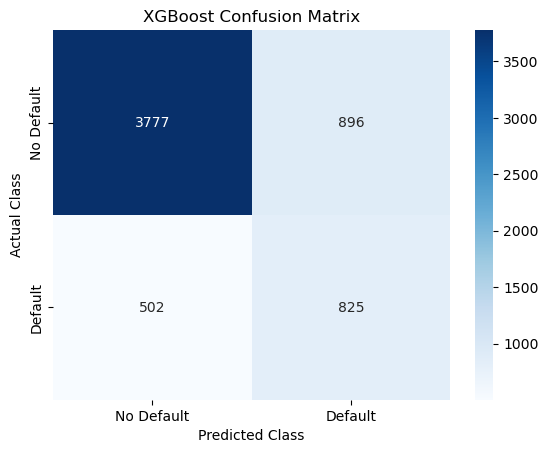

In [34]:
# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred_xgb)

# Visualise the confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Default', 'Default'],
    yticklabels=['No Default', 'Default']
)

# Add chart labels and title
plt.title('XGBoost Confusion Matrix')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

# Display the chart
plt.show()

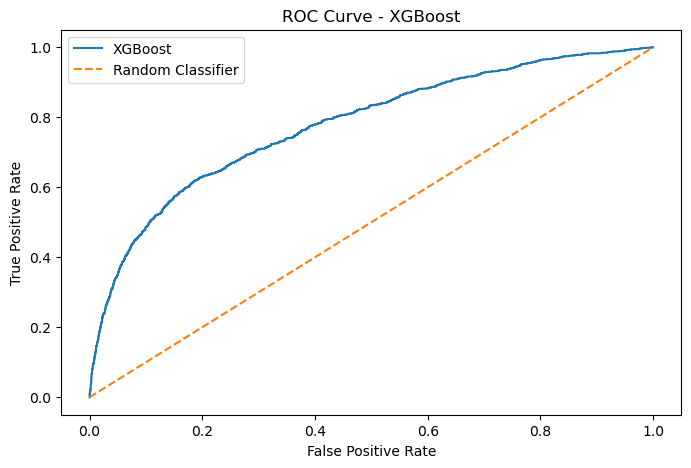

In [35]:
# Import ROC curve calculation function
from sklearn.metrics import roc_curve

# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, y_prob_xgb)

# Plot the ROC curve
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label='XGBoost')

# Plot the random classifier reference line
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

# Add labels and title
plt.title('ROC Curve - XGBoost')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()

# Display the chart
plt.show()

In [36]:
# Import SHAP for model explainability

import shap

In [39]:
# Create a SHAP explainer for the trained XGBoost model
explainer = shap.TreeExplainer(xgb_model)

# Calculate SHAP values for the test dataset
shap_values = explainer(X_test)

# Display the SHAP values dimensions
print("SHAP values shape:", shap_values.values.shape)

SHAP values shape: (6000, 23)


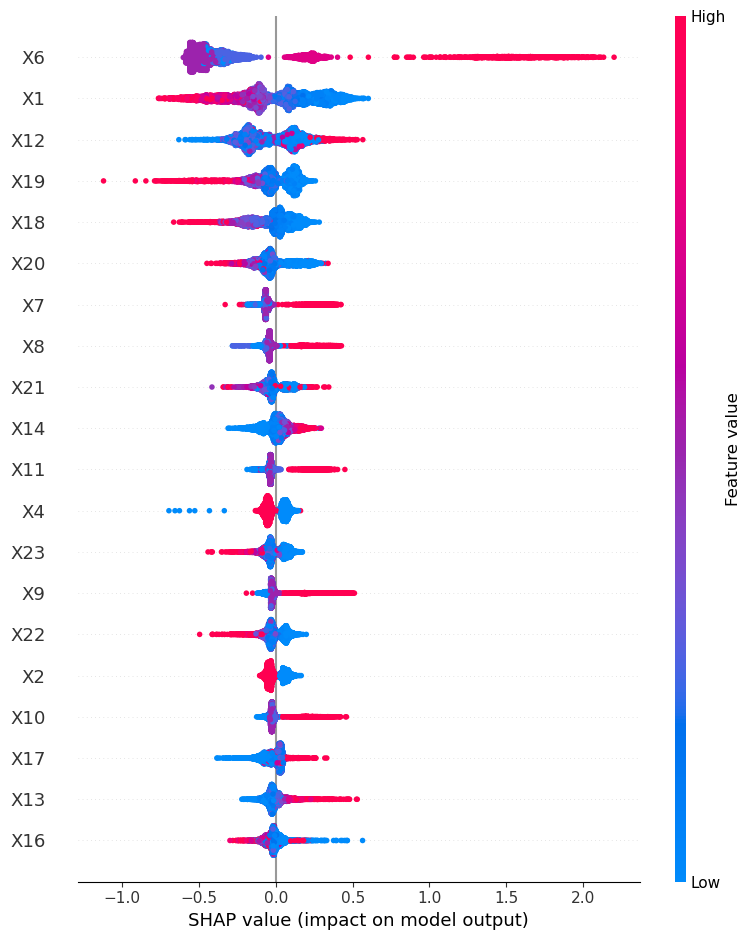

In [40]:
# Display the global importance and impact of each feature
shap.summary_plot(shap_values, X_test)

In [41]:
# Map anonymised feature names to their actual meanings
feature_mapping = {
    'X1': 'Credit_Limit',
    'X2': 'Gender',
    'X3': 'Education',
    'X4': 'Marital_Status',
    'X5': 'Age',
    'X6': 'Repayment_Status_1',
    'X7': 'Repayment_Status_2',
    'X8': 'Repayment_Status_3',
    'X9': 'Repayment_Status_4',
    'X10': 'Repayment_Status_5',
    'X11': 'Repayment_Status_6',
    'X12': 'Bill_Amount_1',
    'X13': 'Bill_Amount_2',
    'X14': 'Bill_Amount_3',
    'X15': 'Bill_Amount_4',
    'X16': 'Bill_Amount_5',
    'X17': 'Bill_Amount_6',
    'X18': 'Payment_Amount_1',
    'X19': 'Payment_Amount_2',
    'X20': 'Payment_Amount_3',
    'X21': 'Payment_Amount_4',
    'X22': 'Payment_Amount_5',
    'X23': 'Payment_Amount_6'
}

# Create a renamed copy of the test features for SHAP visualisation
X_test_named = X_test.rename(columns=feature_mapping)

# Display the updated feature names
print(X_test_named.columns.tolist())

['Credit_Limit', 'Gender', 'Education', 'Marital_Status', 'Age', 'Repayment_Status_1', 'Repayment_Status_2', 'Repayment_Status_3', 'Repayment_Status_4', 'Repayment_Status_5', 'Repayment_Status_6', 'Bill_Amount_1', 'Bill_Amount_2', 'Bill_Amount_3', 'Bill_Amount_4', 'Bill_Amount_5', 'Bill_Amount_6', 'Payment_Amount_1', 'Payment_Amount_2', 'Payment_Amount_3', 'Payment_Amount_4', 'Payment_Amount_5', 'Payment_Amount_6']


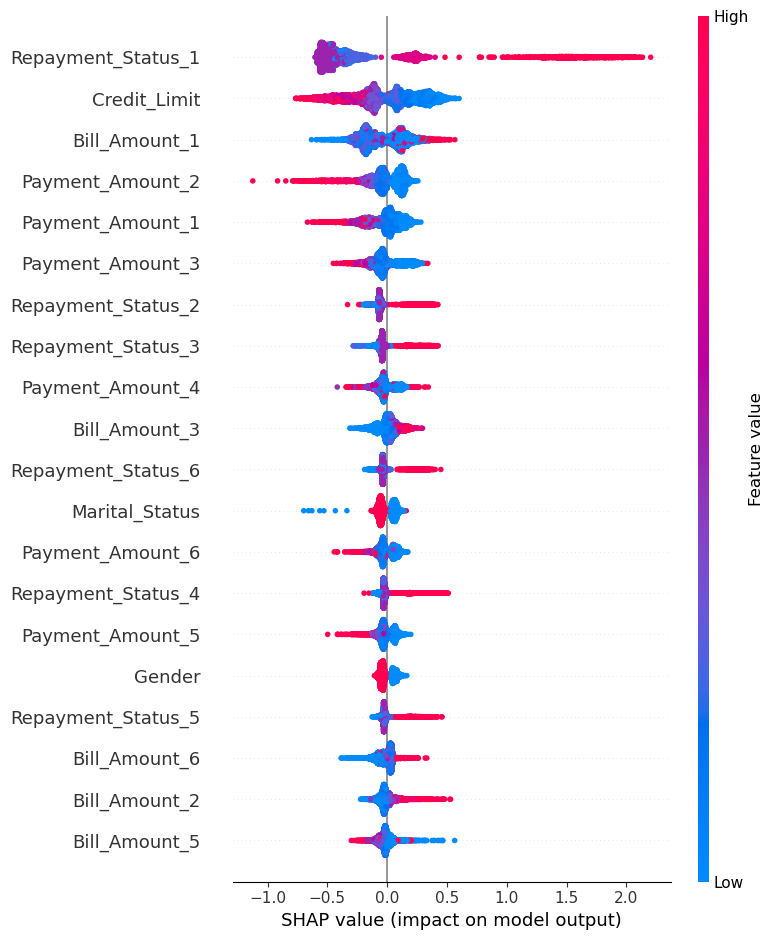

In [42]:
# Display SHAP summary plot with meaningful feature names
shap.summary_plot(
    shap_values.values,
    X_test_named
)

In [43]:
# Calculate the average absolute SHAP value for each feature
shap_importance = pd.DataFrame({
    'Feature': X_test_named.columns,
    'Mean_Absolute_SHAP': np.abs(shap_values.values).mean(axis=0)
})

# Sort features from most to least important
shap_importance = shap_importance.sort_values(
    by='Mean_Absolute_SHAP',
    ascending=False
).reset_index(drop=True)

# Display the top 10 most important features
shap_importance.head(10).round(4)

,Feature,Mean_Absolute_SHAP
0,Repayment_Status_1,0.5318
1,Credit_Limit,0.2307
2,Bill_Amount_1,0.1557
3,Payment_Amount_2,0.1200
4,Payment_Amount_1,0.1057
5,Payment_Amount_3,0.0975
6,Repayment_Status_2,0.0956
7,Repayment_Status_3,0.0799
8,Payment_Amount_4,0.0624
9,Bill_Amount_3,0.0613


### Conclusion

This project developed a machine learning-based credit risk model to predict the likelihood of customers defaulting on their credit card payments in the following month, using the UCI Default of Credit Card Clients dataset.

Logistic Regression was initially implemented as a baseline model and compared against XGBoost. XGBoost achieved better overall performance, with an accuracy of **76.70%**, precision of **47.94%**, recall of **62.17%**, F1-score of **54.13%**, and ROC-AUC of **77.75%**.

The confusion matrix showed that the XGBoost model correctly identified 825 out of 1,327 actual defaulters, while missing 502 defaulters. This highlights the importance of balancing the identification of high-risk customers against incorrectly flagging customers who would not default.

SHAP explainability was used to understand the factors influencing the model's predictions. Recent repayment status emerged as the most influential feature, followed by credit limit, recent bill amount, and previous payment amounts. These findings highlight the importance of repayment behaviour and customer credit information in assessing default risk.

Overall, the project demonstrates how machine learning and model explainability can support credit risk assessment by identifying customers with a higher likelihood of default. However, the model should be considered a predictive prototype rather than a production-ready credit decision system. Further validation, probability calibration, threshold optimisation, fairness assessment, and testing on more recent and representative lending data would be required before real-world deployment.